In [2]:
import sys, json
sys.path.append("..")
%load_ext autoreload
%autoreload 2

import torch
from torch.utils.data import DataLoader
from src.tokenizer import CharTokenizer
from src.dataset import SQLDataset, collate
from src.model import GPTConfig, TinyGPT

def load(name):
    return [json.loads(line) for line in open(f"../data/raw/{name}.jsonl", encoding="utf-8")]

train = load("train")
tok = CharTokenizer.build([r["question"] for r in train] + [r["sql"] for r in train])
print("vocab size:", tok.vocab_size)

vocab size: 73


In [3]:
config = GPTConfig(vocab_size=tok.vocab_size)
model = TinyGPT(config)

loader = DataLoader(SQLDataset(train, tok), batch_size=4, shuffle=True,
                    collate_fn=lambda b: collate(b, tok.pad_id))
xb, yb = next(iter(loader))

out = model(xb)
print("input :", xb.shape)
print("output:", out.shape)

n_params = sum(p.numel() for p in model.parameters())
print("parameters:", n_params)

input : torch.Size([4, 253])
output: torch.Size([4, 253, 128])
parameters: 44160


In [4]:
from src.model import Head

config = GPTConfig(vocab_size=73)
head = Head(config, head_size=32)

# 1. Shapes
x = torch.randn(2, 10, 128)
print("output:", head(x).shape)                 # expect [2, 10, 32]

# 2. The causality test: change ONLY the last token, check who notices
head.eval()                                     # dropout off so results are repeatable
x = torch.randn(1, 8, 128)
out1 = head(x)
x2 = x.clone()
x2[:, -1, :] = torch.randn(128)                 # replace the last token with something else
out2 = head(x2)

print("earlier tokens unchanged:", torch.allclose(out1[:, :-1], out2[:, :-1]))   # expect True
print("last token changed:      ", not torch.allclose(out1[:, -1], out2[:, -1]))  # expect True

output: torch.Size([2, 10, 32])
earlier tokens unchanged: True
last token changed:       True


In [5]:
import sys, json, math
sys.path.append("..")
%load_ext autoreload
%autoreload 2

import torch
from src.tokenizer import CharTokenizer
from src.dataset import SQLDataset, collate
from src.model import GPTConfig, TinyGPT

def load(name):
    return [json.loads(line) for line in open(f"../data/raw/{name}.jsonl", encoding="utf-8")]

train = load("train")
tok = CharTokenizer.build([r["question"] for r in train] + [r["sql"] for r in train])

ds = SQLDataset(train, tok)
xb, yb = collate([ds[i] for i in range(4)], tok.pad_id)   # the same 4 examples every time
print("vocab size:", tok.vocab_size, "| batch:", xb.shape)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
vocab size: 73 | batch: torch.Size([4, 253])


In [6]:
torch.manual_seed(0)
model = TinyGPT(GPTConfig(vocab_size=tok.vocab_size))

print("parameters:", sum(p.numel() for p in model.parameters()))   # expect 845312

logits, loss = model(xb, yb)
print("logits:", logits.shape)
print("loss:", round(loss.item(), 4), "| random-guess level:", round(math.log(tok.vocab_size), 4))

parameters: 845312
logits: torch.Size([4, 253, 73])
loss: 4.3248 | random-guess level: 4.2905


In [7]:
model.eval()
x = xb[:1, :50].clone()
l1, _ = model(x)

x2 = x.clone()
x2[0, -1] = (x2[0, -1] + 1) % tok.vocab_size      # change only the last token
l2, _ = model(x2)

print("earlier positions unchanged:", torch.allclose(l1[:, :-1], l2[:, :-1], atol=1e-5))
print("last position changed:      ", not torch.allclose(l1[:, -1], l2[:, -1]))

earlier positions unchanged: True
last position changed:       True


In [8]:
torch.manual_seed(0)
model = TinyGPT(GPTConfig(vocab_size=tok.vocab_size, dropout=0.0))
opt = torch.optim.AdamW(model.parameters(), lr=1e-3)

model.train()
for step in range(201):
    logits, loss = model(xb, yb)
    opt.zero_grad()
    loss.backward()
    opt.step()
    if step % 40 == 0:
        print(step, round(loss.item(), 4))

0 4.3344
40 0.3045
80 0.0407
120 0.0203
160 0.013
200 0.0092


In [9]:
model.eval()
for i in range(4):
    row = train[i]
    prompt = torch.tensor([tok.encode(row["question"]) + [tok.sep_id]])
    out = model.generate(prompt, max_new_tokens=300, eos_id=tok.eos_id)
    predicted = tok.decode(out[0, prompt.shape[1]:].tolist())
    print(predicted == row["sql"], "|", predicted[:70])

True | SELECT AVG(price) FROM products WHERE category = 'electronics'
True | SELECT AVG(price) FROM products WHERE category = 'stationery'
True | SELECT AVG(price) FROM products WHERE category = 'toys'
True | SELECT COUNT(*) FROM orders JOIN customers ON orders.customer_id = cus


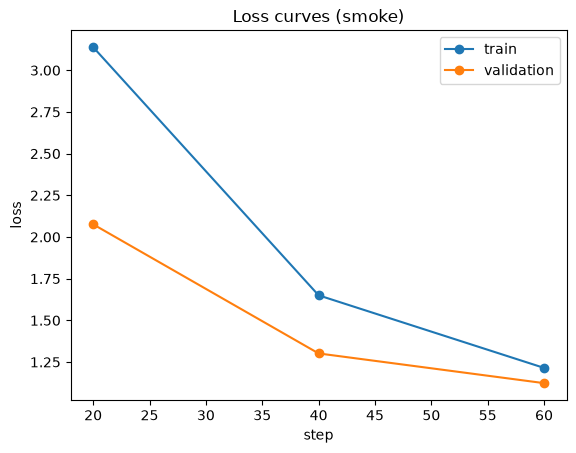

In [11]:
import json
import matplotlib.pyplot as plt

run = "smoke"
history = json.load(open(f"../results/{run}_history.json"))
steps = [h["step"] for h in history]

plt.plot(steps, [h["train_loss"] for h in history], marker="o", label="train")
plt.plot(steps, [h["val_loss"] for h in history], marker="o", label="validation")
plt.xlabel("step")
plt.ylabel("loss")
plt.title(f"Loss curves ({run})")
plt.legend()
plt.savefig(f"../results/loss_curve_{run}.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
import json, re
from collections import Counter
from src.data.make_dataset import skeleton
from src.data.make_db import FIRST_NAMES, CITIES, PRODUCTS

examples = json.load(open("../results/base_val_eval.json"))["examples"]
ALL_PRODUCTS = [p for names in PRODUCTS.values() for p in names]


def literals(sql):
    """Every quoted string and bare number in a query, in order."""
    found = re.findall(r"'[^']*'|\b\d+(?:\.\d+)?\b", sql)
    return [t.strip("'") for t in found]


def slot_type(v):
    if v in CITIES: return "city"
    if v in FIRST_NAMES: return "customer name"
    if v in PRODUCTS: return "category"
    if v in ALL_PRODUCTS: return "product"
    if re.fullmatch(r"\d{4}-\d{2}-\d{2}", v): return "date"
    return "price number"


# 1. What kind of mistake is each failure?
kinds = Counter()
for r in examples:
    if r["exec_correct"]:
        kinds["correct"] += 1
    elif skeleton(r["predicted"]) != skeleton(r["gold"]):
        kinds["wrong SQL structure"] += 1
    else:
        wrong = [p for g, p in zip(literals(r["gold"]), literals(r["predicted"])) if g != p]
        real = all(p in set(FIRST_NAMES) | set(CITIES) | set(PRODUCTS) | set(ALL_PRODUCTS) for p in wrong)
        kinds["right structure, wrong but real value" if real
              else "right structure, misspelled value"] += 1

print("=== kinds of result ===")
for k, n in kinds.most_common():
    print(f"{n:4d}  {k}")

# 2. How often is each type of value copied wrongly?
totals, errors = Counter(), Counter()
for r in examples:
    g, p = literals(r["gold"]), literals(r["predicted"])
    if len(g) != len(p):
        continue
    for gv, pv in zip(g, p):
        totals[slot_type(gv)] += 1
        errors[slot_type(gv)] += gv != pv

print("\n=== copy errors by value type ===")
for t in totals:
    print(f"{t:14s} {totals[t]:4d} values, {errors[t]:3d} wrong ({errors[t] / totals[t]:.0%})")

=== kinds of result ===
 100  correct
  22  right structure, misspelled value
  10  right structure, wrong but real value
   3  wrong SQL structure

=== copy errors by value type ===
category         18 values,   6 wrong (33%)
city             11 values,   6 wrong (55%)
date             54 values,   0 wrong (0%)
customer name    36 values,   9 wrong (25%)
product          12 values,  10 wrong (83%)
price number     12 values,   3 wrong (25%)


In [17]:
import json
rows = [json.loads(l) for l in open("../data/v2/val.jsonl", encoding="utf-8")]
for r in rows[::150]:
    print(r["question"], "->", r["sql"][:90])

add up everything befir ordered -> SELECT SUM(quantity) FROM orders JOIN customers ON orders.customer_id = customers.id WHERE
count the orders made on 2026-02-18 -> SELECT COUNT(*) FROM orders WHERE order_date = '2026-02-18'
how many monitor items have been bought altogether? -> SELECT SUM(quantity) FROM orders JOIN products ON orders.product_id = products.id WHERE pr
how many units of chair were ordered in total? -> SELECT SUM(quantity) FROM orders JOIN products ON orders.product_id = products.id WHERE pr
number of orders dated 2026-01-26 -> SELECT COUNT(*) FROM orders WHERE order_date = '2026-01-26'
tell me how many orders were made following 2026-01-19 -> SELECT COUNT(*) FROM orders WHERE order_date > '2026-01-19'
what did poreda order? -> SELECT DISTINCT products.name FROM orders JOIN customers ON orders.customer_id = customers
what quantity of knife was ordered overall? -> SELECT SUM(quantity) FROM orders JOIN products ON orders.product_id = products.id WHERE pr


In [18]:
import sys, json, random, re
sys.path.append("..")
from src.dataset import augment_example

rows = [json.loads(l) for l in open("../data/v2/train.jsonl", encoding="utf-8")]

random.seed(1)
for r in random.sample(rows, 5):
    q, s = augment_example(r["question"], r["sql"], random, p=1.0)
    print(r["question"], "->", q)
    print("    SQL ends:", s[-55:])

# Every quoted word in the SQL must also appear in the question (dates excepted)
bad = 0
for r in rows:
    q, s = augment_example(r["question"], r["sql"], random, p=1.0)
    for v in re.findall(r"'([^']*)'", s):
        if not re.fullmatch(r"\d{4}-\d{2}-\d{2}", v) and v not in q:
            bad += 1
print("SQL value missing from question:", bad)     # expect 0

how many orders came in on 2026-05-29? -> how many orders came in on 2026-05-29?
    SQL ends: CT COUNT(*) FROM orders WHERE order_date = '2026-05-29'
count the orders made on 2026-06-10 -> count the orders made on 2026-06-10
    SQL ends: CT COUNT(*) FROM orders WHERE order_date = '2026-06-10'
number of orders dated 2026-05-17 -> number of orders dated 2026-05-17
    SQL ends: CT COUNT(*) FROM orders WHERE order_date = '2026-05-17'
how many garden orders came from chennai? -> how many lugibabubo orders came from zgdpamntyy?
    SQL ends: tegory = 'lugibabubo' AND customers.city = 'zgdpamntyy'
which products did raresu order? -> which products did qhyoprhlh order?
    SQL ends: uct_id = products.id WHERE customers.name = 'qhyoprhlh'
SQL value missing from question: 0


In [1]:
import sys, random
sys.path.append("..")
%load_ext autoreload
%autoreload 2
from src.dataset import random_word

random.seed(3)
words = [random_word(random) for _ in range(2000)]
print(words[:8])
print("share with a doubled letter:", sum(any(a == b for a, b in zip(w, w[1:])) for w in words) / len(words))
print("longest word:", max(map(len, words)))

['etsssi', 'yuhezafuuis', 'nzeddinjmrskat', 'wrssusddppnay', 'byykibccg', 'mapesugul', 'mutiiee', 'rimabinijimoo']
share with a doubled letter: 0.6245
longest word: 14


In [2]:
%cd /content/Tiny_Transformer_Lab
import json, re
from collections import Counter

ex = json.load(open("results/v2aug3_test_eval.json"))["examples"]
fails = [r for r in ex if not r["exec_correct"]]
amb = [r for r in fails if r["question"].startswith("tell me the order count for")]
others = [r for r in fails if r not in amb]
print(f"{len(fails)} failures: {len(amb)} from the ambiguous phrase, {len(others)} others")
print("gold value in the other failures:", Counter(re.findall(r"'([^']*)'", r["gold"])[-1] for r in others))


[WinError 3] The system cannot find the path specified: '/content/Tiny_Transformer_Lab'
C:\Users\makar\Python\tiny-transformer-lab\notebooks


FileNotFoundError: [Errno 2] No such file or directory: 'results/v2aug3_test_eval.json'

In [3]:
import json
rows = [json.loads(l) for l in open("../data/v2/paraphrase.jsonl", encoding="utf-8")]
for r in rows[::12]:
    print(r["question"], "->", r["sql"][-60:])

buyers of grater, please list them -> ders.product_id = products.id WHERE products.name = 'grater'
enumerate the items filed under kitchen -> SELECT name FROM products WHERE category = 'kitchen'
how many orders arrived later than 2026-05-30? -> SELECT COUNT(*) FROM orders WHERE order_date > '2026-05-30'
how often has facewash been purchased? -> rs.product_id = products.id WHERE products.name = 'facewash'
mean price for the kitchen group -> SELECT AVG(price) FROM products WHERE category = 'kitchen'
patna buyers: how many clothing orders? ->  products.category = 'clothing' AND customers.city = 'patna'
total ordered quantity for customer liru -> ers.customer_id = customers.id WHERE customers.name = 'liru'
what is the most budget friendly kitchen product? -> oducts WHERE category = 'kitchen' ORDER BY price ASC LIMIT 1
which of our customers are based in patna? -> SELECT name FROM customers WHERE city = 'patna'
